In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# 1. Load the dataset
df = pd.read_csv("pima indians diabetes.csv")

# 2. Inspect first few rows and structure
print("--- Shape of Dataset ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- First 5 Rows ---")
display(df.head())

print("\n--- Column Info & Data Types ---")
df.info()

print("\n--- Summary Statistics ---")
display(df.describe().T)

--- Shape of Dataset ---
Rows: 767, Columns: 9

--- First 5 Rows ---


,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0



--- Column Info & Data Types ---
<class 'pandas.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   6       767 non-null    int64  
 1   148     767 non-null    int64  
 2   72      767 non-null    int64  
 3   35      767 non-null    int64  
 4   0       767 non-null    int64  
 5   33.6    767 non-null    float64
 6   0.627   767 non-null    float64
 7   50      767 non-null    int64  
 8   1       767 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

--- Summary Statistics ---


,count,mean,std,min,25%,50%,75%,max
6,767.0,3.842243,3.370877,0.000,1.0000,3.000,6.000,17.00
148,767.0,120.859192,31.978468,0.000,99.0000,117.000,140.000,199.00
72,767.0,69.101695,19.368155,0.000,62.0000,72.000,80.000,122.00
35,767.0,20.517601,15.954059,0.000,0.0000,23.000,32.000,99.00
0,767.0,79.903520,115.283105,0.000,0.0000,32.000,127.500,846.00
33.6,767.0,31.990482,7.889091,0.000,27.3000,32.000,36.600,67.10
0.627,767.0,0.471674,0.331497,0.078,0.2435,0.371,0.625,2.42
50,767.0,33.219035,11.752296,21.000,24.0000,29.000,41.000,81.00
1,767.0,0.348110,0.476682,0.000,0.0000,0.000,1.000,1.00


In [9]:
# 1. Assign proper column names to the dataset
columns = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

# Reload the CSV specifying names
df = pd.read_csv("pima indians diabetes.csv", names=columns)

# 2. Check summary statistics
print("--- Dataset Shape ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

print("--- Summary Statistics (Check min values for 0s) ---")
display(df.describe().T)

--- Dataset Shape ---
Rows: 768, Columns: 9

--- Summary Statistics (Check min values for 0s) ---


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [10]:
# List of columns where 0 represents a missing value
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

# Count zeros in these columns
zero_counts = (df[zero_cols] == 0).sum()
zero_percentages = (df[zero_cols] == 0).mean() * 100

missing_summary = pd.DataFrame({
    'Zero Count': zero_counts,
    'Percentage (%)': zero_percentages.round(2)
})

print("--- Missing Values (Zeros) Summary ---")
display(missing_summary)

--- Missing Values (Zeros) Summary ---


,Zero Count,Percentage (%)
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


# EXPLORATORY DATA ANALYSIS 

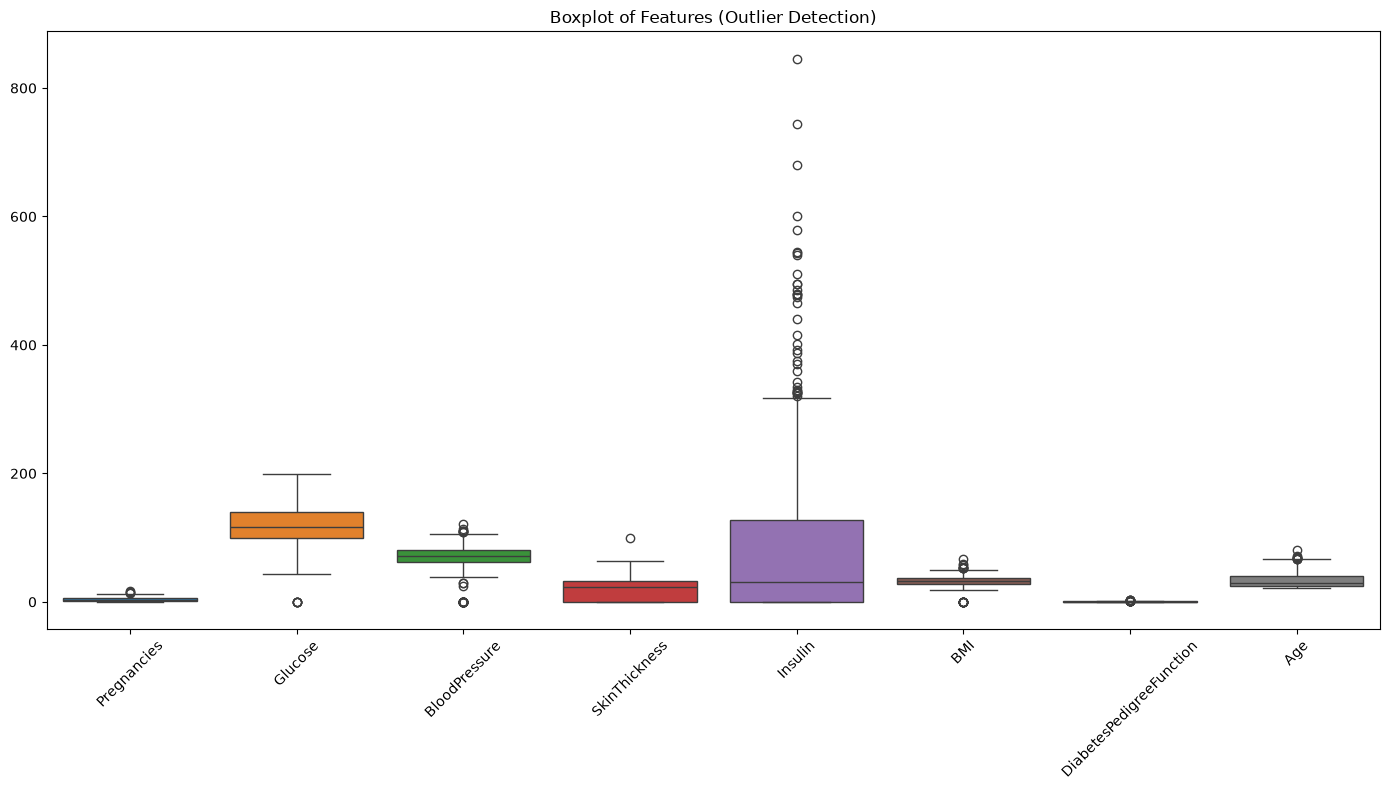

--- Outcome Distribution ---
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


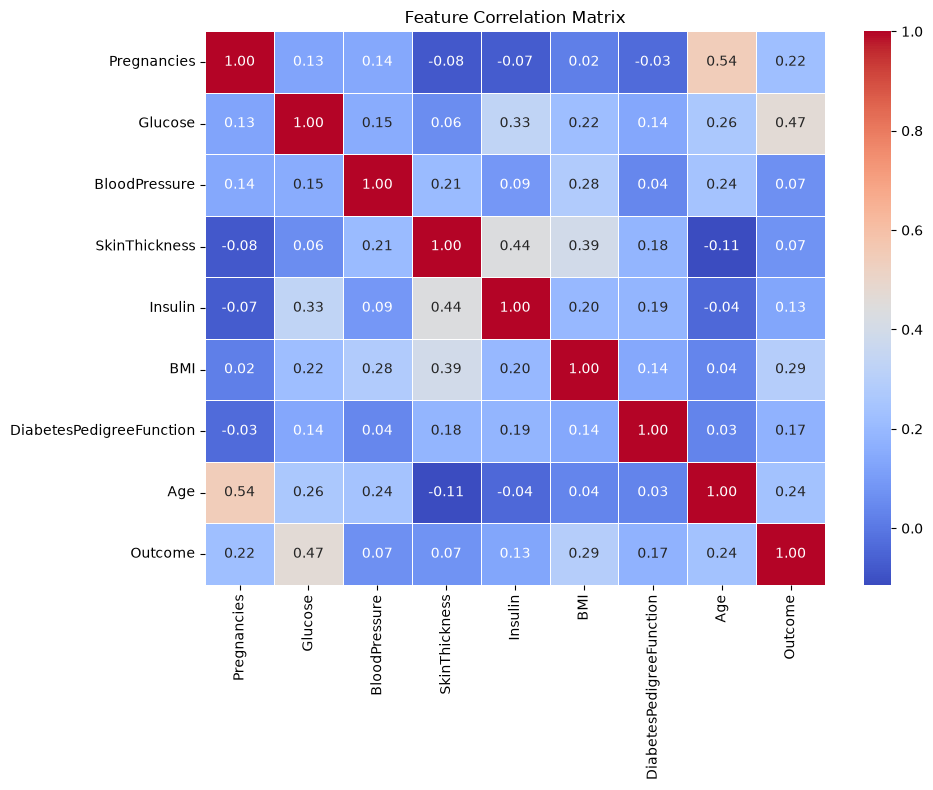

In [11]:
# 1. Boxplots to check for outliers
plt.figure(figsize=(14, 8))
sns.boxplot(data=df.drop(columns=['Outcome']))
plt.title("Boxplot of Features (Outlier Detection)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Target Variable Balance
print("--- Outcome Distribution ---")
print(df['Outcome'].value_counts(normalize=True) * 100)

# 3. Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

# DATA PROCESSING

In [12]:
# Create a clean copy
df_clean = df.copy()

# Replace 0 with NaN in physiological features
zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df_clean[zero_cols] = df_clean[zero_cols].replace(0, np.nan)

# Impute missing values using the median of each class (Outcome)
for col in zero_cols:
    df_clean[col] = df_clean[col].fillna(df_clean.groupby('Outcome')[col].transform('median'))

print("--- Check Missing Values After Imputation ---")
print(df_clean[zero_cols].isnull().sum())

--- Check Missing Values After Imputation ---
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Feature Engineering: Create a BMI-Age health interaction feature
df_clean['BMI_Age_Interaction'] = df_clean['BMI'] * df_clean['Age']

# 2. Define Features (X) and Target (y)
X = df_clean.drop(columns=['Outcome'])
y = df_clean['Outcome']

# 3. Stratified Train-Test Split (preserves class ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Scale features (crucial for models like Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (614, 9)
Testing set shape: (154, 9)


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Initialize models
models = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# Train and evaluate
for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]
        
    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred))
    print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}\n")

=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.77      0.79      0.78       100
           1       0.59      0.56      0.57        54

    accuracy                           0.71       154
   macro avg       0.68      0.67      0.67       154
weighted avg       0.70      0.71      0.71       154

ROC-AUC Score: 0.8265

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.90      0.91      0.91       100
           1       0.83      0.81      0.82        54

    accuracy                           0.88       154
   macro avg       0.87      0.86      0.86       154
weighted avg       0.88      0.88      0.88       154

ROC-AUC Score: 0.9518



c:\Users\DELL\Downloads\Diabetes Prediction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<Figure size 1000x600 with 0 Axes>

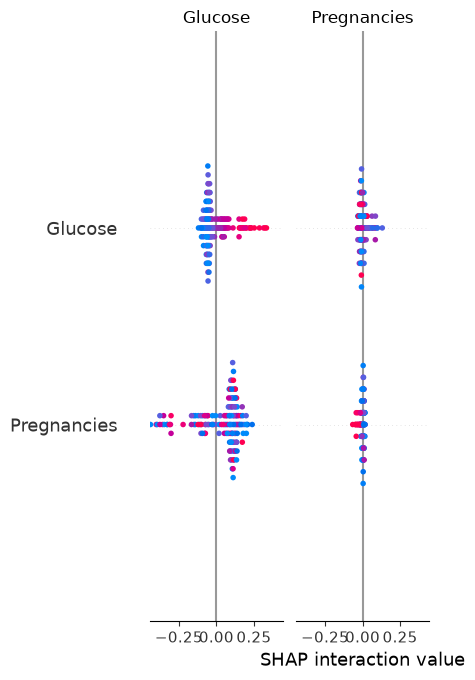

In [15]:
import shap

# Initialize SHAP Explainer using the Random Forest model
explainer = shap.TreeExplainer(models["Random Forest"])
shap_values = explainer.shap_values(X_test)

# Plot summary plot of feature importances
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test, plot_type="bar")

In [16]:
import joblib

# Save artifacts to root folder
joblib.dump(models["Random Forest"], "diabetes_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "feature_columns.pkl")

print("--- Model artifacts successfully saved! ---")

--- Model artifacts successfully saved! ---


In [18]:
import joblib
import numpy as np
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel

# Initialize FastAPI app
app = FastAPI(
    title="Diabetes Prediction API",
    description="End-to-end Machine Learning API for predicting diabetes risk.",
    version="1.0",
)

# Load saved artifacts
model = joblib.load("diabetes_model.pkl")
scaler = joblib.load("scaler.pkl")
feature_columns = joblib.load("feature_columns.pkl")


# Define Pydantic request schema matching our input features
class DiabetesInput(BaseModel):
    Pregnancies: float
    Glucose: float
    BloodPressure: float
    SkinThickness: float
    Insulin: float
    BMI: float
    DiabetesPedigreeFunction: float
    Age: float


@app.get("/")
def home():
    return {"message": "Welcome to the Diabetes Prediction API! Use /docs to test endpoints."}


@app.post("/predict_diabetes")
def predict_diabetes(data: DiabetesInput):
    # 1. Convert input data to DataFrame
    input_data = pd.DataFrame([data.dict()])

    # 2. Perform same feature engineering as training (BMI_Age_Interaction)
    input_data["BMI_Age_Interaction"] = (
        input_data["BMI"] * input_data["Age"]
    )

    # 3. Ensure columns match training order
    input_data = input_data[feature_columns]

    # 4. Make prediction and get probability
    prediction = int(model.predict(input_data)[0])
    probability = float(model.predict_proba(input_data)[0][1])

    # 5. Format response
    result = "Positive for Diabetes" if prediction == 1 else "Negative for Diabetes"

    return {
        "prediction_code": prediction,
        "result": result,
        "probability": round(probability * 100, 2),
    }